# Supplemental Figure 5, Panel E

Fold enrichment (or depletion) IFNg or Dex-inducible elements within enhancers, promoters, and CTCF cREs. 

*Output: PanelE.pdf*

# Setup

In [1]:
#load packages
library(tidyverse)
library(ggrastr)
library(patchwork)
library(RColorBrewer)
library(here)
here::i_am("figures/SuppFig5/PanelE/PanelE.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig5/PanelE

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         RColorBrewer_1.1-3 patchwork_1.3.0    ggrastr_1.0.2     
 [5] lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4       
 [9] purrr_1.0.2        readr_2.1.5        tidyr_1.3.1        tibble_3.2.1      
[13] ggplot2_3.5.2      tidyverse_2.0.0   

loaded 

# Load data

In [2]:
#annotated ATAC-seq peaks
row_meta <- read.delim(
  here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot.tsv"),
  sep = "\t"
)

# differential accessibility results
dar_IFN_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_1h.tsv"),
  sep = "\t"
)

dar_IFN_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_6h.tsv"),
  sep = "\t"
)

dar_Dex_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_1h.tsv"),
  sep = "\t"
)

dar_Dex_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_6h.tsv"),
  sep = "\t"
)



# Generate plots

Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'ifn_ind'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'ifn_ind'. You can override using the
`.groups` argument.


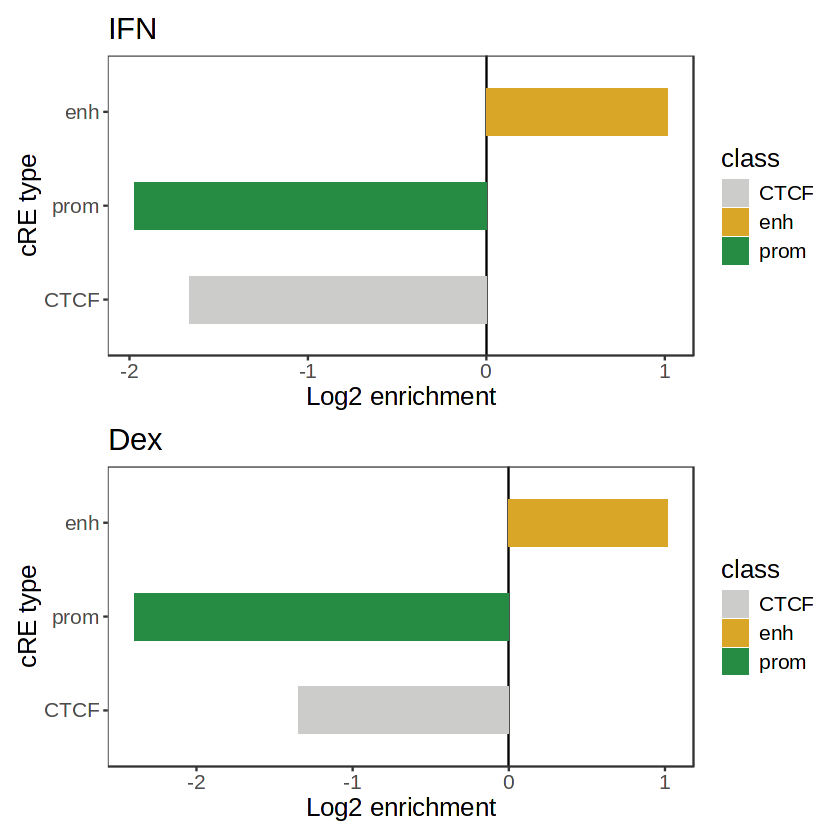

In [3]:
p2 <- row_meta %>% mutate(ifn_ind = dar_Dex_1h$change=="up" | dar_Dex_6h$change == "up", 
                   class= case_when(!TSS & !H3K4me3 & !H3K27me3 & !CTCF & H3K4me1 ~ "enh", 
                                    !TSS & !H3K4me3 & !H3K27me3 & CTCF ~ "CTCF",
                                    TSS & H3K4me3 ~ "prom",
                                    TRUE ~ "other"))  %>% 
    filter(class != "other") %>%
    # calculate % of IFNg inducible elements in each cRE class
    group_by(ifn_ind, class) %>% summarize(n=n(), .groups="drop") %>% group_by(ifn_ind) %>% summarize(class,n,pct=100*n/sum(n)) %>%
    select(!n) %>%
    pivot_wider(names_from="ifn_ind", values_from="pct") %>% 
    # calculate fold change enrichment/depletion of IFNg-inducible elements in each cRE class
    mutate(ratio=log2(`TRUE`/`FALSE`)) %>%
    ggplot(aes(y=factor(class, levels=c("CTCF", "prom", "enh")),x=ratio, fill=class)) + 
    geom_vline(xintercept=0) + 
    geom_col(width=.5) +
    ggtitle("Dex") +
    scale_fill_manual(values=c("CTCF"="#cccccb", "enh"="#daa628", "prom"="#268c43")) + xlab("Log2 enrichment") + ylab("cRE type")

p1 <- row_meta %>% mutate(ifn_ind = dar_IFN_1h$change=="up" | dar_IFN_6h$change == "up", 
                   class= case_when(!TSS & !H3K4me3 & !H3K27me3 & !CTCF & H3K4me1 ~ "enh", 
                                    !TSS & !H3K4me3 & !H3K27me3 & CTCF ~ "CTCF",
                                    TSS & H3K4me3 ~ "prom",
                                    TRUE ~ "other"))  %>% 
    filter(class != "other") %>%
    # calculate % of Dex inducible elements in each cRE class
    group_by(ifn_ind, class) %>% summarize(n=n(), .groups="drop") %>% group_by(ifn_ind) %>% summarize(class,n,pct=100*n/sum(n)) %>%
    select(!n) %>%
    pivot_wider(names_from="ifn_ind", values_from="pct") %>% 
    # calculate fold change enrichment/depletion of Dex-inducible elements in each cRE class
    mutate(ratio=log2(`TRUE`/`FALSE`)) %>%
    ggplot(aes(y=factor(class, levels=c("CTCF", "prom", "enh")),x=ratio, fill=class)) + 
    geom_vline(xintercept=0) + 
    geom_col(width=.5) +
    ggtitle("IFN") +
    scale_fill_manual(values=c("CTCF"="#cccccb", "enh"="#daa628", "prom"="#268c43")) + xlab("Log2 enrichment") + ylab("cRE type")

p1 / p2
ggsave("PanelE.pdf", width=4, height=6)

# Statistics

In [4]:
pvals_ifn <- c()
ors_ifn <- c()

pvals_dex <- c()
ors_dex<- c()

#for each cRE type, use Fisher's exact test to assess enrichment for stim-responsive elements (for each of IFNg and Dex)
types <- c("enh", "prom", "CTCF")
for(cre_class in types) {
    test_ifn <- row_meta %>% mutate(ifn_ind = dar_IFN_1h$change=="up" | dar_IFN_6h$change == "up", 
                   class= case_when(!TSS & !H3K4me3 & !H3K27me3 & !CTCF & H3K4me1 ~ "enh", 
                                    !TSS & !H3K4me3 & !H3K27me3 & CTCF ~ "CTCF",
                                    TSS & H3K4me3 ~ "prom",
                                    TRUE ~ "other"))  %>% 
    filter(class != "other") %>% 
    select(ifn_ind, class) %>%
    mutate(class=class==cre_class) %>%
    table() %>%
    fisher.test()

    test_dex <- row_meta %>% mutate(dex_ind = dar_Dex_1h$change=="up" | dar_Dex_6h$change == "up", 
                   class= case_when(!TSS & !H3K4me3 & !H3K27me3 & !CTCF & H3K4me1 ~ "enh", 
                                    !TSS & !H3K4me3 & !H3K27me3 & CTCF ~ "CTCF",
                                    TSS & H3K4me3 ~ "prom",
                                    TRUE ~ "other"))  %>% 
    filter(class != "other") %>% 
    select(dex_ind, class) %>%
    mutate(class=class==cre_class) %>%
    table() %>%
    fisher.test()

    pvals_ifn[cre_class] <- test_ifn$p.value
    ors_ifn[cre_class] <- test_ifn$estimate

    pvals_dex[cre_class] <- test_dex$p.value
    ors_dex[cre_class] <- test_dex$estimate
}

pvals_ifn
pvals_dex
ors_ifn
ors_dex

enh          prom          CTCF 
7.368244e-139  2.068791e-45  2.281697e-56

enh          prom          CTCF 
6.328363e-283 5.934372e-119  1.755724e-91

enh      prom      CTCF 
6.9631899 0.2049636 0.2321419

enh      prom      CTCF 
6.5727443 0.1495297 0.2968887